# Local model case study

These are actual local model measurements, separate from the original synthetic demonstrations. Both companion papers share this study. Read `empirical/PROTOCOL.md` for limits and the frozen analysis. This notebook loads completed observations; it does not run or fabricate model outcomes.

In [1]:
from pathlib import Path
import pandas as pd
root = Path.cwd() if (Path.cwd() / 'empirical').exists() else Path.cwd().parent
episodes = pd.read_csv(root / 'empirical/results/episodes.csv')
assert len(episodes) == 720
assert not episodes.duplicated(['model','task_id','architecture','condition','seed']).any()
assert episodes.output_tokens.max() <= 512
assert episodes.infrastructure_error.isna().all()
print('720 unique recorded attempts, including unsuccessful attempts')

720 unique recorded attempts, including unsuccessful attempts


In [2]:
summary = pd.read_csv(root / 'empirical/results/condition_summary.csv')
summary[['model','architecture','condition','correct','episodes','exposed','post_exposure_success']]

Out[2]: 
                                  model  ... post_exposure_success
0   HuggingFaceTB/SmolLM2-360M-Instruct  ...                   NaN
1   HuggingFaceTB/SmolLM2-360M-Instruct  ...                   NaN
2   HuggingFaceTB/SmolLM2-360M-Instruct  ...                   NaN
3   HuggingFaceTB/SmolLM2-360M-Instruct  ...                   NaN
4   HuggingFaceTB/SmolLM2-360M-Instruct  ...                   NaN
5   HuggingFaceTB/SmolLM2-360M-Instruct  ...                   NaN
6   HuggingFaceTB/SmolLM2-360M-Instruct  ...                   NaN
7   HuggingFaceTB/SmolLM2-360M-Instruct  ...                   NaN
8   HuggingFaceTB/SmolLM2-360M-Instruct  ...              0.000000
9   HuggingFaceTB/SmolLM2-360M-Instruct  ...              0.000000
10                      Qwen/Qwen3-0.6B  ...                   NaN
11                      Qwen/Qwen3-0.6B  ...              0.083333
12                      Qwen/Qwen3-0.6B  ...              0.166667
13                      Qwen/Qwen3-0.6B  ...         

## Clean-condition accuracy

The plotted means are descriptive. Use the released task-cluster confidence intervals; 720 repeated episodes are not 720 independent tasks. SA has no tool-fault condition. Zero exposure is unobserved, not a passed recovery or safety test.

Out[3]: <Axes: xlabel='architecture', ylabel='Exact-answer accuracy'>


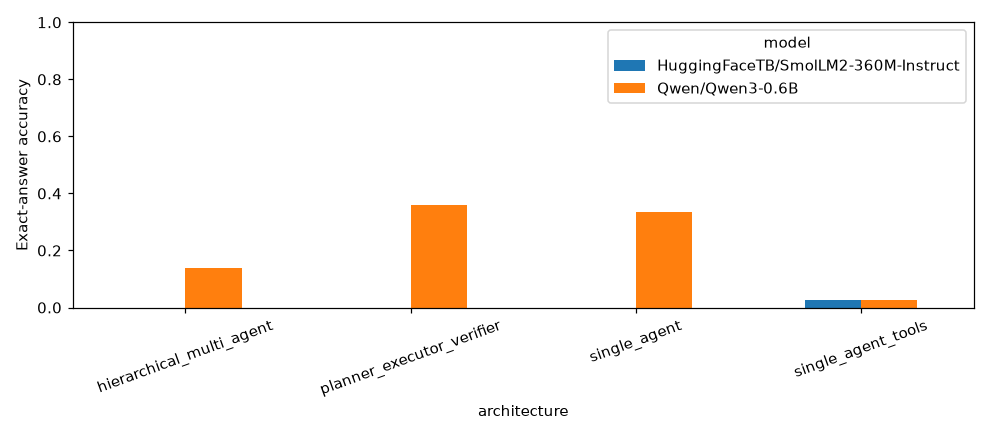

In [3]:
clean = summary.loc[summary.condition.eq('clean')]
clean.pivot(index='architecture', columns='model', values='accuracy').plot.bar(ylim=(0,1), ylabel='Exact-answer accuracy', rot=20, figsize=(9,4))

In [4]:
policies = pd.read_csv(root / 'empirical/results/selector_policy_evaluation.csv')
policies[['model','policy','mean_utility','ci_low','ci_high','mean_observed_regret']]

Out[4]: 
                                 model  ... mean_observed_regret
0  HuggingFaceTB/SmolLM2-360M-Instruct  ...             0.025933
1  HuggingFaceTB/SmolLM2-360M-Instruct  ...             0.031288
2  HuggingFaceTB/SmolLM2-360M-Instruct  ...             0.053784
3  HuggingFaceTB/SmolLM2-360M-Instruct  ...             0.034622
4  HuggingFaceTB/SmolLM2-360M-Instruct  ...             0.052406
5                      Qwen/Qwen3-0.6B  ...             0.109258
6                      Qwen/Qwen3-0.6B  ...             0.411328
7                      Qwen/Qwen3-0.6B  ...             0.091778
8                      Qwen/Qwen3-0.6B  ...             0.311141
9                      Qwen/Qwen3-0.6B  ...             0.091580

[10 rows x 6 columns]


The fixed selector uses unvalidated question-only proxies and unchanged coefficients. The observed oracle uses only three trials per task/configuration. No complete FDAR aggregate, broad enterprise claim, independent peer review or arXiv publication is implied.